# Group nearby counterpoint IDs under the same identifier

Since anyone can create a Counterpoint pin in the app, there are many sites with multiple Counterpoint pins at or near the same location. These should be considered the same count location for analysis. This script finds counterpoint IDs that are within 100 metres of each other and chooses the ID that was an official count site in 2021 or the most-used ID as the grouped ID. 

Steps:
- get metadata for counterpoint locations from counterpoint API
- load data for all count years and get list of IDs, including paper counts
- group nearby counterpoints
- create table with original and grouped counterpoint IDs

Tests:
- [x] all original valid counterpoints are retained
- [x] all counterpoints mapped to the same grouped counterpoint are within 100 m of each other (exception when multiple clusters overlap - check visually)


In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
from matplotlib import pyplot as plt

In [2]:
pd.options.mode.copy_on_write = True

In [3]:
official_count_ids_2021 = pd.read_csv("data/Official Count Locations IDs.csv")

In [4]:
data_2021_url = "https://velocanadabikes.org/wp-content/uploads/2022/Pedal%20Poll%202021%20Data%20UPLOAD.csv"
data_2021 = pd.read_csv(data_2021_url)
data_files = [data_2021]

for year in [2022, 2023, 2024]:
    data_files.append(pd.read_csv("data/%s_cleaned_data.csv" %year, low_memory=False))

In [5]:
original_counterpoints = []
for data in data_files:
    original_counterpoints += list(data['counterpoint_id'].drop_duplicates())

In [6]:
years = [2021, 2022, 2023, 2024]
counterpoint_ids_list = []
for i, year in enumerate(years):
    counterpoints = data_files[i][['counterpoint_id', 'lat', 'lng', 
                                   'geocoded_city', 'geocoded_province']].drop_duplicates()
    # sometimes the hand count also has a row, but we can keep the lat/lng from the app data if there's also an app count
    counterpoints = counterpoints.drop_duplicates(subset = 'counterpoint_id', keep = 'first')
    counterpoints['year'] = year
    counterpoint_ids_list.append(counterpoints)

In [7]:
counterpoint_ids = pd.concat(counterpoint_ids_list)

In [8]:
# how many are present in multiple years?
year_counts = counterpoint_ids.groupby(['counterpoint_id'])['year'].count().reset_index()

In [9]:
# remove rows with no counterpoint ID
num_na = counterpoint_ids[counterpoint_ids['counterpoint_id'].isna()].shape[0]
print(num_na)
# can't do anything with an NA counterpoint ID after doing my best to search
counterpoint_ids = counterpoint_ids[~counterpoint_ids['counterpoint_id'].isna()]

2


In [10]:
# unique counterpoint IDs - year combinations in total
counterpoint_ids.shape

(984, 6)

In [11]:
# number of unique counterpoint ids
year_counts.shape

(584, 2)

In [12]:
assert len(list(set(original_counterpoints))) - num_na == counterpoint_ids['counterpoint_id'].drop_duplicates().shape[0]

In [13]:
# number shared between years before any spatial matching
print("Before spatial matching, %s counterpoint IDs are present in multiple years." %(year_counts[year_counts['year'] > 1].shape[0]))

Before spatial matching, 237 counterpoint IDs are present in multiple years.


In [14]:
# test: shouldn't be more years than number of pedal polls
total_years = len(years)
assert year_counts[year_counts['year'] > total_years].empty

### Get missing lat/long info for counterpoints

In [15]:
import requests
from tqdm import tqdm

In [16]:
# counterpoints with missing metadata, usually from paper counts
missing_data = counterpoint_ids[np.any(counterpoint_ids[['lat', 'lng', 'geocoded_city', 'geocoded_province']].isna(), axis = 1)]

In [17]:
missing_data[missing_data['counterpoint_id'] == 5888]

,counterpoint_id,lat,lng,geocoded_city,geocoded_province,year


In [18]:
# initialize country column
missing_data['geocoded_country'] = np.nan
missing_data['geocoded_country'] = missing_data['geocoded_country'].astype('object')

In [19]:
for i, row in tqdm(missing_data.iterrows()):
    # get counterpoint data from the api
    response = requests.get("https://api.counterpointapp.org/api/v2/counterpoints/{}".format(row['counterpoint_id']))
    missing_data.loc[i, 'lat'] = response.json()['lat']
    missing_data.loc[i, 'lng'] = response.json()['lng']
    missing_data.loc[i, 'geocoded_city'] = response.json()['geocoded_city']
    missing_data.loc[i, 'geocoded_province'] = response.json()['geocoded_state']
    missing_data.loc[i, 'geocoded_country'] = response.json()['geocoded_country']

37it [00:24,  1.53it/s]


In [20]:
present_data = counterpoint_ids[~np.any(counterpoint_ids[['lat', 'lng', 'geocoded_city', 'geocoded_province']].isna(), axis = 1)]

In [21]:
present_data['geocoded_province'].value_counts()

geocoded_province
Ontario                              421
Alberta                              130
British Columbia                     123
Nova Scotia                           73
Manitoba                              50
Saskatchewan                          36
Yukon                                 23
Newfoundland and Labrador             21
Quebec                                18
New Brunswick / Nouveau-Brunswick     17
Prince Edward Island                  16
Québec                                11
Northwest Territories                  8
Name: count, dtype: int64

In [22]:
# assign Canada, since in data cleaning only locations in Canada were retained
present_data['geocoded_country'] = 'Canada'

In [23]:
shape = counterpoint_ids.shape[0]
# rejoin data
counterpoint_ids = pd.concat([present_data, missing_data])
# confirm same data is retained
assert counterpoint_ids.shape[0] == shape

In [24]:
counterpoint_ids.shape

(984, 7)

In [25]:
counterpoint_ids['geocoded_province'].unique()

array(['Saskatchewan', 'Ontario', 'Yukon', 'British Columbia', 'Alberta',
       'Manitoba', 'Nova Scotia', 'Quebec', 'Prince Edward Island',
       'Newfoundland and Labrador', 'New Brunswick / Nouveau-Brunswick',
       'Québec', 'Northwest Territories', 'יהודה ושומרון',
       'Provincia Heredia'], dtype=object)

In [26]:
# remove the accent in Quebec to standardize
counterpoint_ids.loc[counterpoint_ids['geocoded_province'] == 'Québec', 'geocoded_province'] = 'Quebec'

In [27]:
counterpoint_ids['geocoded_city'] = counterpoint_ids['geocoded_city'].str.strip()

In [28]:
counterpoint_ids['geocoded_city'].sort_values().unique()

array(['Area D (Roberts Creek)', 'Area E (Elphinstone)',
       'Area H (The Slocan Valley)', 'Banff', 'Brampton', 'Bridgewater',
       'Burlington', 'Burnaby', 'Calgary', 'Campbell River', 'Canmore',
       'Capilano No. 5', 'Central Saanich', 'Champlain', 'Charlottetown',
       'City of Charlottetown', 'City of Leduc', 'City of Red Deer',
       'City of Saint John', 'Coldbrook', 'Coquitlam', 'Corner Brook',
       'Cumberland', 'Dartmouth', 'Dieppe', 'District of North Vancouver',
       'Edmonton', 'Elliot Lake', 'Fredericton', 'Gatineau', 'Glace Bay',
       'Goulbourn', 'Guelph', 'Halifax', 'Hamilton',
       'Head of Chezzetcook', 'Hebbville', 'Kamloops', 'Kanata',
       'Kelowna', 'Kingston', 'Kitchener', 'London', 'Lunenburg',
       'Maple Ridge', 'Medicine Hat', 'Mississauga', 'Moncton',
       'Montreal', 'Montréal', 'Nelson', 'New Glasgow', 'No city',
       'North Dumfries', 'North Vancouver', 'Oakville', 'Orillia',
       'Ottawa', 'Paradise', 'Peterborough', 'Port Co

In [29]:
# fix "no city" labels
# sometimes the city is missing for one entry with that ID but not others - get the other name if possible
for c_id, group in counterpoint_ids.groupby('counterpoint_id'):
    if np.any(group['geocoded_city'].str.contains('No city')):
        try:
            other_name = group[group['geocoded_city'] != 'No city']['geocoded_city'].unique()[0]
            print(group[group['geocoded_city'] != 'No city']['geocoded_city'].unique())
            counterpoint_ids.loc[counterpoint_ids['counterpoint_id'] == c_id, 'geocoded_city'] = other_name
        except:
            pass

['Saskatoon']
['Ottawa']
['Ottawa']


In [30]:
# group city names - more city grouping will come later
counterpoint_ids.loc[counterpoint_ids['geocoded_city'] == 'City of Charlottetown', 'geocoded_city'] = 'Charlottetown'
counterpoint_ids.loc[counterpoint_ids['geocoded_city'] == 'City of Red Deer', 'geocoded_city'] = 'Red Deer'
counterpoint_ids.loc[counterpoint_ids['geocoded_city'] == 'Central Saanich', 'geocoded_city'] = 'Saanich'
counterpoint_ids.loc[counterpoint_ids['geocoded_city'] == 'Montréal', 'geocoded_city'] = 'Montreal'
counterpoint_ids.loc[counterpoint_ids['geocoded_city'] == 'Kanata', 'geocoded_city'] = 'Ottawa'

In [31]:
counterpoint_ids['geocoded_country'].value_counts()

geocoded_country
Canada                   982
Palestinian Territory      1
Costa Rica                 1
Name: count, dtype: int64

In [32]:
counterpoint_ids[~(counterpoint_ids['geocoded_country'] == 'Canada')]['counterpoint_id'].drop_duplicates()

49018    3738.0
19396    3944.0
Name: counterpoint_id, dtype: float64

In [33]:
# keep only IDs mapped to Canada - these probably represent improperly recorded IDs from the paper count
not_canada = counterpoint_ids[~(counterpoint_ids['geocoded_country'] == 'Canada')]['counterpoint_id'].drop_duplicates().shape[0]
counterpoint_ids = counterpoint_ids[counterpoint_ids['geocoded_country'] == 'Canada']

In [34]:
# check that counterpoints are retained
assert len(list(set(original_counterpoints))) - num_na - not_canada == counterpoint_ids['counterpoint_id'].drop_duplicates().shape[0]

### Convert to geodataframe, group IDs based on buffer

In [35]:
#make sure they all have lat lng info
assert np.any(counterpoint_ids[['lat', 'lng']].isna()) == False

In [36]:
gdf = gpd.GeoDataFrame(
    counterpoint_ids, geometry=gpd.points_from_xy(counterpoint_ids['lng'], counterpoint_ids['lat']), crs="EPSG:4326")

In [37]:
# this is so handy - chooses a utm projection based on the bounds of the dataset!
gdf_utm = gdf.to_crs(gdf.estimate_utm_crs())
print(gdf_utm.crs)

EPSG:32615


In [38]:
import contextily as cx

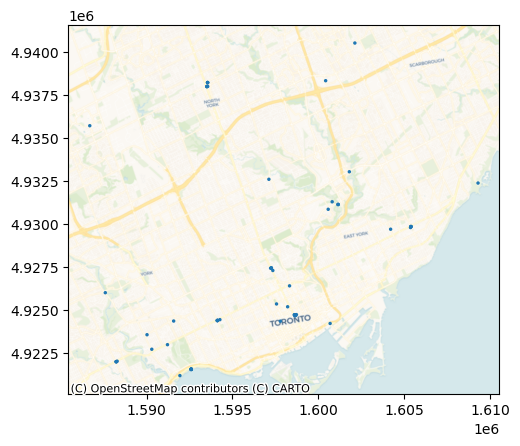

In [39]:
# example: counterpoint IDs in Toronto
fig, ax = plt.subplots()
gdf_utm[gdf_utm['geocoded_city'] == 'Toronto'].buffer(100).plot(ax = ax)
cx.add_basemap(ax, crs = gdf_utm.crs, source=cx.providers.CartoDB.Voyager)

In [40]:
from geopandas.tools import sjoin

In [41]:
# use 50 metre radius, so points within 100 metres of each other will be joined
gdf_utm['geometry']= gdf_utm.buffer(50)

In [42]:
# just focus on unique counterpoint IDs regardless of year
gdf_utm = gdf_utm.drop(columns = ['year', 'lat', 'lng']).drop_duplicates()

In [43]:
# spatial join to itself, default is by intersection
intersects = gpd.sjoin(gdf_utm, gdf_utm)

(4824500.0, 4828000.0)

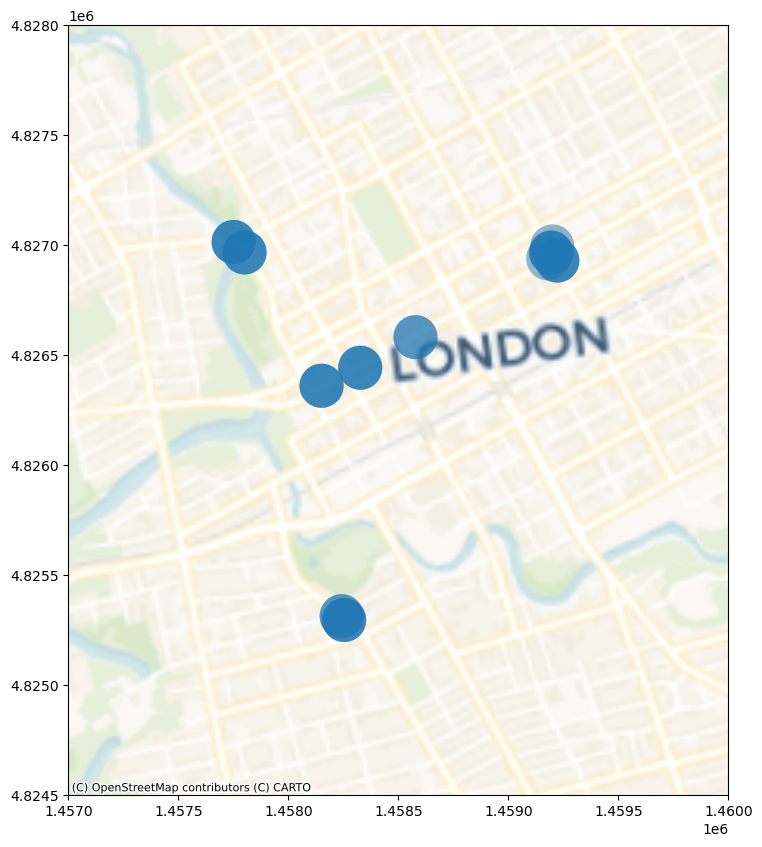

In [44]:
# example: London, ON
fig, ax = plt.subplots(figsize = (10,10))
gdf_utm[gdf_utm['geocoded_city'] == 'London'].buffer(50).plot(ax = ax, alpha = 0.5)
cx.add_basemap(ax, crs = gdf_utm.crs, source=cx.providers.CartoDB.Voyager)

ax.set_xlim(1.457e6, 1.460e6)
ax.set_ylim(4.8245e6, 4.828e6)

(4826500.0, 4827500.0)

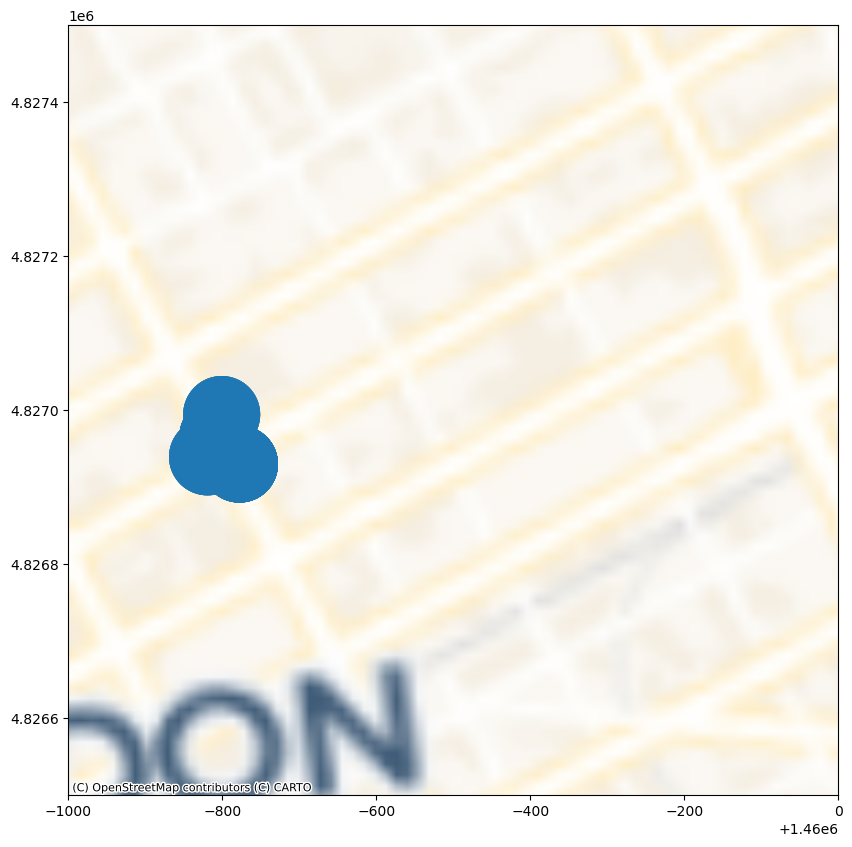

In [45]:
# example: 4 overlapping
fig, ax = plt.subplots(figsize = (10,10))
intersects[intersects['geocoded_city_left'] == 'London'].plot(ax = ax, alpha = 0.5)
cx.add_basemap(ax, crs = gdf_utm.crs, source=cx.providers.CartoDB.Voyager)

ax.set_xlim(1.459e6, 1.460e6)
ax.set_ylim(4.8265e6, 4.8275e6)

The merge ends up with $n^2$ fields where $n$ is the number of overlapping points. 

A 2-way merge ends up with 4 fields: A-A, A-B, B-A, B-B

3-way (9):
A-A
B-B
C-C
A-B
B-A
A-C
C-A
B-C
C-B

4-way (16), etc.

### Group overlapping counterpoints and assign to official counterpoint ID, otherwise assign to the one that is most common

Using the `intersects` object, find pairs that overlap and group.

Process:
- get list of grouped IDs 
- check if any of them are in the official data
- if not, check year_counts to see which one is most common
- if equal, choose one at random
- check if there are any overlapping groups - are there any ids present in multiple groups?

In [46]:
# remove self intersections
intersects_diff = intersects[~(intersects['counterpoint_id_left'] == intersects['counterpoint_id_right'])][['counterpoint_id_left', 
                                                                        'counterpoint_id_right']].drop_duplicates()

In [47]:
print(len(intersects_diff))

574


In [48]:
unique_overlapping_ids = intersects_diff[['counterpoint_id_left', 'counterpoint_id_right']].drop_duplicates()['counterpoint_id_left'].unique()

In [49]:
all_groups = []

for counterpoint_id in unique_overlapping_ids:
    df = intersects_diff[intersects_diff['counterpoint_id_left'] == counterpoint_id]
    grouped_ids = set(list(df.values.flatten())) # use sets in order to compare permutations
    
    all_groups.append(grouped_ids)

In [50]:
# remove duplicate sets from having both directions of pairing
# every entry is duplicated at minimum because of the left-right + right-left intersection pair
seen = []
for x in all_groups:
    if x not in seen:
        seen.append(x)

In [51]:
# this is the final number of clusters to resolve
num_clusters = len(seen)

In [52]:
# merge clusters with overlap
# from https://stackoverflow.com/a/56641351
merging = True
while merging:
    merging=False
    for i,group in enumerate(seen):
        merged = next((g for g in seen[i+1:] if g.intersection(group)),None)
        if not merged: continue
        group.update(merged)
        seen.remove(merged)
        merging = True

In [53]:
len(seen)

86

In [54]:
print("%s clusters were merged together because they overlapped with other clusters." %(num_clusters - len(seen)))

5 clusters were merged together because they overlapped with other clusters.


Iterate through clusters and assign common id. The official count IDs from 2021 also sometimes include overlapping sites, so group these by counterpoint name FIRST and then choose one.

Count locations within 100m of another location were merged, unless the official count site name indicated separate directions (i.e. Blackfriars East/West and Blackfriars North/South).

In [55]:
# check if any clusters contain the same key - they should now be non-overlapping
visited_ids = []
for cluster in seen:
    for c_id in cluster:
        assert c_id not in visited_ids
    visited_ids += list(cluster)    

In [56]:
# to map to grouped key
group_dict_definitions = {} # key is mapped id, value is list of keys mapped to it
group_dict = {} # key is original id, value is mapped id

for cluster in seen:
    # check if any of the IDs are official count sites
    official_ids = official_count_ids_2021[official_count_ids_2021['counterpoint_id'].isin(cluster)]
    # sometimes two nearby sites are actually separate official sites, if so try to keep separate
    if official_ids.drop_duplicates(subset = 'Name').shape[0] == len(cluster): # don't group
        print(official_ids)
        continue
    else: # need to choose one counterpoint ID
        if official_ids.shape[0] > 1: # need to choose from among the official IDs
            # look for which sites are most used
            present_counts = year_counts[year_counts['counterpoint_id'].isin(official_ids['counterpoint_id'])].sort_values(by = 'year', 
                                                                                                                           ascending = False)
            grouped_id = present_counts.iloc[0]['counterpoint_id'] # this will just take the first one if they're all the same count
            # also record grouping for the official count locations to note that we grouped some official locations together
            for c_id in official_ids['counterpoint_id']:
                group_dict[int(c_id)] = int(grouped_id)
        elif official_ids.shape[0] == 1: #use this one
            grouped_id = official_ids['counterpoint_id']
        else: # no official id from group, check year counts
            present_counts = year_counts[year_counts['counterpoint_id'].isin(cluster)].sort_values(by = 'year', ascending = False)
            grouped_id = present_counts.iloc[0]['counterpoint_id'] # this will just take the first one if they're all the same count
    group_dict_definitions[int(grouped_id)] = list(cluster)       
    for c_id in cluster:
        group_dict[int(c_id)] = int(grouped_id)
                                                                  

                         Name  counterpoint_id
79      Blackfriars East/West             5366
80  Blackfriars (North/South)             5372
                               Name  counterpoint_id
140  Burrard & Cornwall - West Side             5309
141  Burrard & Cornwall - East Side             5310


/tmp/ipykernel_47845/891419601.py:26: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  group_dict_definitions[int(grouped_id)] = list(cluster)
/tmp/ipykernel_47845/891419601.py:28: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  group_dict[int(c_id)] = int(grouped_id)
/tmp/ipykernel_47845/891419601.py:26: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  group_dict_definitions[int(grouped_id)] = list(cluster)
/tmp/ipykernel_47845/891419601.py:28: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  group_dict[int(c_id)] = int(grouped_id)


118.26289186840147
197.6586655978241


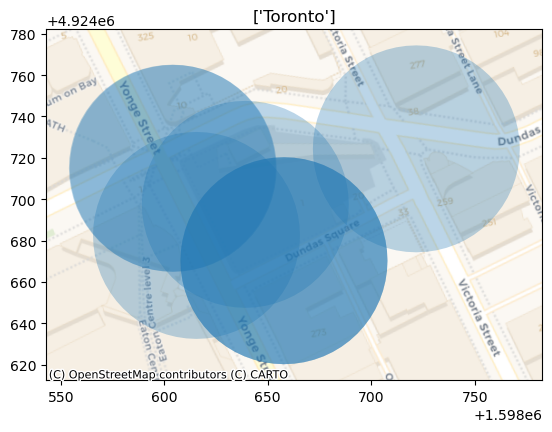

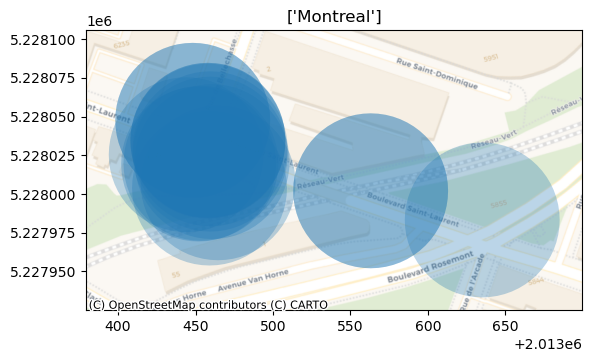

In [57]:
# test:
# check that all points in a cluster are within 100 metres of each other
# if not, plot the cluster to check
gdf_utm = gdf.to_crs(gdf.estimate_utm_crs())

for key, value in group_dict_definitions.items():
    df = gdf_utm[gdf_utm['counterpoint_id'].isin(value)]
    max_distance = 0
    for i, row in df.iterrows(): # calculate distance to all other points in the cluster
        dist = df.distance(row['geometry'])
        if np.max(dist) > max_distance:
            max_distance = np.max(dist)
    total_bounds = df.total_bounds # this 
    try:
        #assert total_bounds[2] - total_bounds[0] <= 100 # x bounds
        #assert total_bounds[3] - total_bounds[1] <= 100 # y bounds
        assert max_distance <= 100
    except: # check by plotting
        print(max_distance)
        fig, ax = plt.subplots()
        df.buffer(50).plot(ax = ax, alpha = 0.3)
        ax.set_title(df['geocoded_city'].unique())
        cx.add_basemap(ax, crs = df.crs, source=cx.providers.CartoDB.Voyager)

In [58]:
# create the mapped column
counterpoint_ids['grouped_counterpoint_id'] = counterpoint_ids['counterpoint_id'].map(group_dict)
# fill non-mapped values with the original ID
counterpoint_ids['grouped_counterpoint_id'] = counterpoint_ids['grouped_counterpoint_id'].fillna(counterpoint_ids['counterpoint_id'])

In [59]:
counterpoint_ids[counterpoint_ids['grouped_counterpoint_id'] == 5519]

,counterpoint_id,lat,lng,geocoded_city,geocoded_province,year,geocoded_country,grouped_counterpoint_id
34637,5519.0,49.914647,-97.141971,Winnipeg,Manitoba,2021,Canada,5519.0
47167,5519.0,49.914650,-97.141970,Winnipeg,Manitoba,2022,Canada,5519.0
13717,5519.0,49.914647,-97.141971,Winnipeg,Manitoba,2024,Canada,5519.0
19369,5519.0,49.914647,-97.141971,Winnipeg,Manitoba,2023,Canada,5519.0


In [60]:
# how many are present in multiple years?
year_counts_grouped = counterpoint_ids[['grouped_counterpoint_id', 
                                        'year']].drop_duplicates().groupby(['grouped_counterpoint_id'])['year'].count().reset_index()

In [61]:
# unique counterpoint ID-year combinations in total
counterpoint_ids.shape

(982, 8)

In [62]:
# original number of unique ids 
len(set(original_counterpoints))

586

In [63]:
# number of unique counterpoint ids after grouping
year_counts_grouped.shape

(430, 2)

In [64]:
assert year_counts_grouped[year_counts_grouped['year'] > total_years].empty

In [65]:
print("After grouping there are %s sites that had data for all %s years" 
      %(year_counts_grouped[year_counts_grouped['year'] == total_years].shape[0], total_years))

After grouping there are 62 sites that had data for all 4 years


In [66]:
print("After grouping nearby count sites, there are {} sites that had counts in ".format(year_counts_grouped[year_counts_grouped['year'] == 2].shape[0]) +
      "two years")
print(" and {} sites that had counts in three years.".format(year_counts_grouped[year_counts_grouped['year'] == 3].shape[0]))
print(" and {} sites that had counts in four years.".format(year_counts_grouped[year_counts_grouped['year'] == 4].shape[0]))

print("Before grouping nearby count sites, there were {} sites that had counts in ".format(year_counts[year_counts['year'] == 2].shape[0]) +
      "two of the years")
print("and {} sites that had counts in three years.".format(year_counts[year_counts['year'] == 3].shape[0]))
print("and {} sites that had counts in four years.".format(year_counts[year_counts['year'] == 4].shape[0]))
                                                                                         

After grouping nearby count sites, there are 63 sites that had counts in two years
 and 72 sites that had counts in three years.
 and 62 sites that had counts in four years.
Before grouping nearby count sites, there were 119 sites that had counts in two of the years
and 73 sites that had counts in three years.
and 45 sites that had counts in four years.


In [67]:
len(set(original_counterpoints))

586

In [68]:
# test: all original valid counterpoint IDs are retained
assert len(list(set(original_counterpoints))) - num_na - not_canada == counterpoint_ids['counterpoint_id'].drop_duplicates().shape[0]

In [69]:
counterpoint_ids['counterpoint_id'].unique().shape

(582,)

### Get location info for all

In [70]:
# get name and location info for all counterpoint IDs
# this is very slow
# updated to just search on grouped counterpoint id to cut down processing time

for i, row in tqdm(counterpoint_ids.drop_duplicates(subset = 'grouped_counterpoint_id').iterrows()):
    counterpoint_id = row['grouped_counterpoint_id']
    # get counterpoint data from the api
    response = requests.get("https://api.counterpointapp.org/api/v2/counterpoints/{}".format(int(counterpoint_id)))
    counterpoint_ids.loc[counterpoint_ids['grouped_counterpoint_id'] == counterpoint_id, 'grouped_counterpoint_name'] = response.json()['name']
    counterpoint_ids.loc[counterpoint_ids['grouped_counterpoint_id'] == counterpoint_id, 'grouped_counterpoint_lat'] = response.json()['lat']
    counterpoint_ids.loc[counterpoint_ids['grouped_counterpoint_id'] == counterpoint_id, 'grouped_counterpoint_lng'] = response.json()['lng']
    counterpoint_ids.loc[counterpoint_ids['grouped_counterpoint_id'] == counterpoint_id, 'grouped_counterpoint_osm_id'] = response.json()['geocoded_osm_id']

430it [04:30,  1.59it/s]


In [71]:
counterpoint_ids.shape

(982, 12)

In [72]:
# save matching file to identify grouped sites in analysis
counterpoint_ids.sort_values(by = 'grouped_counterpoint_id').to_csv("data/counterpoint_id_groupings.csv", index = None)